# 4. Model Selection and Training

This notebook develops, compares, and selects a machine learning regression model for forecasting actual production quantity (`actual_qty`) in the shoe manufacturing division of DI Leather.

The objective is to identify a model that can learn relationships between production resources, operating conditions, and actual output, then generalise those relationships to later production records.

The notebook is divided into two parts.

**Part A – Model Selection**
1. Load the engineered feature dataset.
2. Separate the predictors and target variable.
3. Divide the records chronologically into training and testing sets.
4. Build a preprocessing pipeline for numerical and categorical variables.
5. Train seven candidate regression models.
6. Evaluate and compare the models using R², MAE, and RMSE.
7. Select the best-performing model based on test results and the train–test performance gap.

**Part B – Final Training and Saving**
1. Retrain the selected model using all available records.
2. Save the complete preprocessing and modelling pipeline.
3. Reload the saved model and verify that it can generate predictions.

The target variable is `actual_qty`. The selected model will provide the predictive component of the project, while the subsequent prescriptive analytics stage can use its predictions to estimate target achievement and production gaps.

Model performance is assessed using a chronological holdout test set, which represents later production observations that were not used to fit the candidate models.

# 4.1 Part A – Model Selection

Model selection involves comparing different algorithms to determine which provides the most reliable predictions for the production forecasting problem.

No single algorithm performs best for every dataset. Some models are designed to capture straightforward linear relationships, while others can learn complex interactions and nonlinear patterns.

Seven regression models are compared using the same training and testing periods and the same preprocessing approach. This provides a consistent basis for evaluating their predictive performance.

The comparison considers both prediction error and generalisation. A model that performs extremely well on training data but substantially worse on unseen data may have overfitted the training observations.

The objective is therefore not simply to select the most complex model or the model with the highest training score. It is to identify the model that performs best on the held-out test period while maintaining a reasonable difference between training and testing performance.

### 4.1.1 Import Libraries and Required Functions

The required libraries are imported for data manipulation, preprocessing, regression modelling, performance evaluation, and model saving.

Scikit-learn provides the regression algorithms, preprocessing transformers, pipelines, and evaluation metrics. XGBoost provides an additional gradient-boosting implementation, while Joblib is used to save and reload the final model.

The evaluation functions include:

- `r2_score`: Measures how well the predictions explain variation in the target.
- `mean_absolute_error`: Calculates the average absolute prediction error.
- `mean_squared_error`: Calculates the mean squared prediction error, from which RMSE is obtained.

The `Pipeline` and `ColumnTransformer` components allow preprocessing and modelling to be managed as one workflow. This ensures that transformations are fitted on the training data rather than independently using information from the test data.

The imported functions provide a consistent framework for comparing the candidate models and preserving the selected model for future predictions.

In [37]:
# DataFrame.to_markdown() needs the 'tabulate' package:  pip install tabulate

import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

### 4.1.2 Load the Feature Dataset

The engineered feature dataset is loaded from `final_features.csv`, and `week_start_date` is parsed as a datetime column.

The dataset contains 9,495 records and 18 columns, including the target variable, the date used to preserve chronological order, and the prepared predictors.

An assertion checks that `week_start_date` is in ascending chronological order. If the records are not correctly ordered, the notebook stops instead of proceeding with an invalid time-based split.

This validation is important because the project forecasts production quantities over time. Training on randomly mixed records could allow observations from later periods to influence a model evaluated on earlier periods, resulting in an unrealistic assessment of forecasting performance.

The date column is retained for ordering and split verification, but it is excluded from the predictors in the model training step.

In [38]:
# Load the final feature dataset
df = pd.read_csv(
    "../data/processed/final_features.csv",
    parse_dates=["week_start_date"]
)

# Verify chronological order
assert df["week_start_date"].is_monotonic_increasing, \
    "Data must be sorted by week_start_date"

print("Dataset shape:", df.shape)

Dataset shape: (9495, 18)


### 4.1.3 Define the Target, Predictors, and Chronological Split

The target variable is `actual_qty`, representing the actual quantity produced for each record.

The predictors are the remaining columns after excluding `actual_qty` and `week_start_date`. The date column is excluded from the model inputs because it is used to preserve the chronological sequence rather than as a direct predictor.

The dataset is divided into two parts:

- **Training set:** The first 80% of the chronologically ordered records.
- **Testing set:** The most recent 20% of the records.

The training set contains 7,596 records, covering 18 April 2022 to 24 March 2025. The test set contains 1,899 records, covering 24 March 2025 to 30 March 2026.

A chronological split is appropriate because the intended application is forecasting future production. The model learns from earlier production records and is evaluated on a later period that it did not use for fitting.

No random shuffling is performed. This preserves the time direction of the prediction problem and gives a more realistic estimate of how the models may perform on later production observations.

The test set is reserved for model comparison and should not be used to fit preprocessing transformations or model parameters.


In [39]:
target = 'actual_qty'

X_full = df.drop(columns=[target, 'week_start_date'])
y_full = df[target]

split_idx = int(len(df) * 0.8)
X_train, X_test = X_full.iloc[:split_idx], X_full.iloc[split_idx:]
y_train, y_test = y_full.iloc[:split_idx], y_full.iloc[split_idx:]

print(f"Train: {len(X_train):,} rows  ({df['week_start_date'].iloc[0].date()} to {df['week_start_date'].iloc[split_idx - 1].date()})")
print(f"Test : {len(X_test):,} rows  ({df['week_start_date'].iloc[split_idx].date()} to {df['week_start_date'].iloc[-1].date()})")

Train: 7,596 rows  (2022-04-18 to 2025-03-24)
Test : 1,899 rows  (2025-03-24 to 2026-03-30)


### 4.1.4 Why a Chronological Split Is Necessary

In a forecasting problem, the order of observations matters because future production records would not be available when predictions are made for an earlier period.

A random train–test split can mix earlier and later observations. This may allow a model to learn patterns from periods that occur after some of the records it is evaluated on, making the evaluation less representative of actual forecasting.

The chronological split avoids this problem by using earlier records for training and later records for testing.

The test results therefore indicate how well each model generalises to a later period under the current evaluation setup. They do not guarantee identical performance in every future period, particularly if production processes or operating conditions change.

The training and testing periods should remain unchanged while comparing the seven candidate models so that the results are directly comparable.


### 4.1.5 Feature Scaling and Preprocessing

Feature scaling is performed using `StandardScaler` inside the modelling pipeline. Each numerical predictor is transformed using the mean and standard deviation learned from the training data:

[
\boxed{z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}}
]

This gives the numerical features a common scale, which can be useful for models such as Linear Regression, Ridge Regression, and Lasso Regression. It is particularly important for regularised linear models because the scale of a predictor can affect the strength of the regularisation applied to its coefficient.

Tree-based models generally do not require standardisation, but the same preprocessing framework is used consistently when comparing the candidate models. The scaler is fitted within each model pipeline, helping prevent information from the held-out test set from influencing preprocessing.

Categorical features are encoded separately, while `bottleneck_flag` remains in its existing binary representation.


### 4.1.6 Build the Preprocessing Pipeline

The dataset contains numerical, binary, and categorical variables. These variable types require different preprocessing methods before being supplied to the regression models.

The preprocessing operations are placed inside a `ColumnTransformer`, which is then included in a modelling pipeline.

The transformations are:

| Transformer | Variables | Purpose |
|---|---|---|
| `StandardScaler` | Numerical features | Standardises each feature using the training data's mean and standard deviation. |
| `OneHotEncoder` | `financial_month`, `factory_unit`, `product_family`, `grade`, `order_category`, `size_id` | Converts categories into binary indicator columns. |
| `TargetEncoder` | `item_name` | Represents each item using a smoothed target-based encoding. |
| `passthrough` | `bottleneck_flag` | Retains the existing 0/1 representation. |

**Why use a pipeline?**

The preprocessing transformations are fitted as part of the model pipeline. When the pipeline is trained, the transformations learn from the training data rather than from the complete dataset.

This is important for preventing information leakage. For example, the scaler should not use the test set's mean and standard deviation, and target encoding should not use the held-out test targets to determine item encodings.

One-hot encoding uses `handle_unknown='ignore'`, allowing the pipeline to handle categories that were not observed during training without failing. For target encoding, unseen items can be represented using the encoder's overall target-based fallback.

Using the same preprocessing design for all candidate models makes the comparison more consistent and ensures that the final saved model contains both the required transformations and the selected regression algorithm.

In [40]:
categorical_ohe = ['financial_month', 'factory_unit', 'product_family', 'grade', 'order_category', 'size_id']
categorical_target = ['item_name']
binary_cols = ['bottleneck_flag']
numerical_cols = [col for col in X_train.columns if col not in categorical_ohe + categorical_target + binary_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_ohe),
        ('cat_te', TargetEncoder(target_type='continuous'), categorical_target),
        ('binary', 'passthrough', binary_cols)
    ])

print("Numeric columns:", numerical_cols)
print("Binary columns :", binary_cols)

Numeric columns: ['week_no', 'week_of_month', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'machine_worker_ratio', 'avg_hours_per_worker']
Binary columns : ['bottleneck_flag']


### 4.1.7 Candidate Regression Models

Seven regression models are evaluated to compare different approaches to predicting actual production quantity.

The models cover three main families:

| Model family | Candidate models | Main purpose |
|---|---|---|
| Linear models | Linear Regression, Ridge Regression, Lasso Regression | Establish a simple relationship between predictors and the target, with regularisation options. |
| Bagged tree models | Random Forest, Extra Trees | Capture nonlinear relationships and interactions using collections of decision trees. |
| Boosted tree models | Gradient Boosting, XGBoost | Build an ensemble sequentially, improving predictions by learning from earlier errors. |

Including different model families is useful because the relationships between workforce, machine availability, operating conditions, and production quantity may not be entirely linear.

Linear models provide interpretable reference points, while tree-based models can learn more complex relationships. Comparing them helps establish whether additional model complexity improves prediction on the held-out production period.

The models are initially compared using the settings specified in the code. Hyperparameter tuning is not performed in this notebook, so the results represent a comparison of these particular model configurations rather than an exhaustive search for the best possible configuration of each algorithm.


### 4.1.8 Rationale for Selecting Each Candidate Model

Each candidate model is included for a specific reason. Comparing them helps determine which modelling approach best represents the production data.

**1. Linear Regression – Baseline Model**

Linear Regression is selected as the baseline model. It estimates a linear relationship between the predictors and `actual_qty`.

The model provides a straightforward reference point for evaluating whether more complex algorithms improve forecasting performance. It is relatively simple to interpret and can show how well the target can be predicted using additive relationships between the prepared features.

Its main limitation is that it cannot automatically capture complex nonlinear relationships unless those relationships are represented through the input features. Nevertheless, it is an important starting point because a complex model should demonstrate a meaningful improvement over a simple alternative.

**2. Ridge Regression – Regularised Linear Model**

Ridge Regression is included to assess whether regularisation improves the linear baseline.

It adds an L2 penalty to the regression objective, discouraging excessively large coefficients. This can help when predictors contain overlapping information or when the model is sensitive to the combination of input variables.

Ridge retains all predictors but can shrink their coefficients towards zero. It is therefore useful for examining whether a regularised linear relationship provides better generalisation than ordinary Linear Regression.

**3. Lasso Regression – Feature-Shrinking Linear Model**

Lasso Regression uses an L1 penalty, which can shrink some coefficients exactly to zero.

This makes it useful for assessing whether a simpler linear model can achieve competitive performance while reducing the influence of less useful predictors. It is particularly relevant when the feature set contains several related variables.

However, Lasso may select one variable from a group of correlated predictors and reduce the coefficients of others. Its performance therefore depends on the data and the regularisation strength.

**4. Random Forest – Bagged Decision Trees**

Random Forest combines predictions from many decision trees trained using randomised samples and feature selections.

It is selected because production relationships may be nonlinear. For example, the relationship between workforce size and output may change depending on machine count, working hours, or other operating conditions.

By averaging predictions from multiple trees, Random Forest can capture interactions and nonlinear patterns without requiring them to be specified manually. Its main risk is overfitting, especially when the trees become too complex relative to the available data.

**5. Gradient Boosting – Sequential Tree Ensemble**

Gradient Boosting builds a sequence of decision trees, with each new tree attempting to reduce the errors made by the current ensemble.

It is selected because it can model nonlinear relationships and interactions while progressively improving the fit to the training data. Its sequential learning process differs from the parallel tree-building approach used by bagged ensembles.

Gradient Boosting often provides a useful balance between predictive flexibility and generalisation when its learning rate, tree complexity, and number of boosting stages are appropriate.

Its performance still depends on the model settings, so the test results must be examined rather than assuming it will outperform the other candidates.

**6. Extra Trees – Highly Randomised Tree Ensemble**

Extra Trees, or Extremely Randomised Trees, combines many decision trees while introducing additional randomness into the choice of split points.

It is included to compare another tree-ensemble approach with Random Forest. The extra randomness can reduce variance and sometimes improve generalisation, although it may also make individual trees less precise.

Extra Trees can capture complex nonlinear patterns and interactions. However, a large gap between training and test performance would indicate that the model fits the training data much more closely than the unseen period.

**7. XGBoost – Optimised Gradient Boosting**

XGBoost is included as an additional gradient-boosting implementation designed for efficient and flexible tree-based learning.

Like Gradient Boosting, it builds an ensemble sequentially, improving predictions through successive boosting stages. It also provides regularisation mechanisms and other controls that can help manage model complexity.

XGBoost is a useful candidate because production data may contain interactions and nonlinear relationships that simpler linear models cannot capture.

However, its more advanced implementation does not guarantee better results. Its performance depends on its hyperparameters and the structure of the dataset, so it must be judged using the same held-out test period as the other models.

In [41]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1)
}

### 4.1.9 Train and Evaluate Every Candidate Model

Each candidate regression model is placed inside a pipeline containing the same preprocessing transformations.

The pipeline is fitted using the training set, then predictions are generated for both the training and test sets. The predictions are evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

Training metrics show how closely the model fits the records used to train it. Test metrics show how well it predicts the later records that were withheld during fitting.

The distinction is important because a model can achieve very low training error by learning patterns that do not generalise to future observations.

All seven models are evaluated using the same split and metrics. This makes it possible to compare predictive accuracy and generalisation under the same conditions.

The results are stored in a comparison table so that the relative strengths and weaknesses of the candidate models can be examined before selecting the final model.

### 4.1.10 Evaluation Metrics: R², MAE, and RMSE

Three regression metrics are used to evaluate the models: R², MAE, and RMSE. Each metric measures a different aspect of prediction performance.

#### 1. R-squared (R²)

R² measures how well the model's predictions explain the variation in the actual target values, relative to predicting the mean of the evaluation targets.

The formula is:

R² = 1 − (Sum of Squared Prediction Errors / Total Sum of Squares)

Interpretation:

- **R² = 1:** Predictions match the actual values perfectly.
- **R² = 0:** The model performs no better than predicting the evaluation-set mean under the standard R² comparison.
- **R² below 0:** The model performs worse than that mean-based reference on the evaluation data.

A higher R² is generally preferable when comparing models on the same test set.

In this project, the selected Gradient Boosting model achieves a test R² of 0.791. This means the model explains approximately 79.1% of the variation in actual production quantity relative to the test-set mean baseline.

This must not be interpreted as 79.1% prediction accuracy or as 79.1% of predictions being correct. R² measures explained variation, not the percentage of exact predictions.

#### 2. Mean Absolute Error (MAE)

MAE measures the average absolute difference between predicted and actual production quantities.

Formula:

MAE = Mean(|Actual Quantity − Predicted Quantity|)

Each prediction error is converted to an absolute value, so overpredictions and underpredictions do not cancel each other out.

A lower MAE is better. The metric is straightforward to interpret because it is expressed in the same units as `actual_qty`.

The selected model has a test MAE of 4.577. This means its predictions differ from actual production quantity by an average absolute amount of approximately 4.58 units per record across the test set.

MAE is useful for communicating typical prediction error to non-technical stakeholders. However, it does not distinguish between a small number of very large errors and a larger number of moderate errors as strongly as RMSE does.

#### 3. Root Mean Squared Error (RMSE)

RMSE is the square root of the mean of the squared prediction errors.

Formula:

RMSE = √Mean((Actual Quantity − Predicted Quantity)²)

Squaring the errors gives greater weight to larger mistakes. Taking the square root returns the metric to the original target scale.

A lower RMSE is better. Because large errors receive a greater penalty, RMSE is useful when substantial forecasting mistakes are particularly undesirable for production planning.

The selected model has a test RMSE of 6.000. This indicates an error magnitude of approximately 6 production units under the RMSE calculation.

RMSE is higher than MAE for this model, as expected when errors vary in size. The difference between the two metrics suggests that larger errors influence RMSE more strongly than the average absolute error alone would indicate.

#### Why use all three metrics?

Using several metrics provides a more complete evaluation:

- **R²** measures explained variation.
- **MAE** describes average absolute prediction error.
- **RMSE** penalises large prediction errors more heavily.

A model with a high R² may still produce errors that are too large for practical planning. Likewise, a model with a low MAE may still make occasional large mistakes.

For this reason, model selection considers the metrics together rather than relying on a single score.

In [42]:
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', clone(preprocessor)), ('model', model)])

    pipeline.fit(X_train, y_train)

    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'Train R²': round(r2_score(y_train, y_train_pred), 3),
        'Test R²': round(r2_score(y_test, y_test_pred), 3),
        'Train MAE': round(mean_absolute_error(y_train, y_train_pred), 3),
        'Test MAE': round(mean_absolute_error(y_test, y_test_pred), 3),
        'Train RMSE': round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 3),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3)
    })

results_df = pd.DataFrame(results)
print(results_df.to_markdown(index=False))

| Model             |   Train R² |   Test R² |   Train MAE |   Test MAE |   Train RMSE |   Test RMSE |
|:------------------|-----------:|----------:|------------:|-----------:|-------------:|------------:|
| Linear Regression |      0.803 |     0.783 |       4.465 |      4.721 |        5.786 |       6.108 |
| Ridge Regression  |      0.804 |     0.784 |       4.459 |      4.714 |        5.775 |       6.102 |
| Lasso Regression  |      0.798 |     0.779 |       4.508 |      4.763 |        5.851 |       6.175 |
| Random Forest     |      0.936 |     0.766 |       2.452 |      4.849 |        3.301 |       6.353 |
| Gradient Boosting |      0.828 |     0.791 |       4.176 |      4.565 |        5.398 |       5.998 |
| Extra Trees       |      0.985 |     0.755 |       0.887 |      4.931 |        1.595 |       6.493 |
| XGBoost           |      0.911 |     0.758 |       2.98  |      4.941 |        3.879 |       6.454 |


### 4.1.11 Interpret the Training and Testing Results

The comparison table contains training and test R², MAE, and RMSE for all seven models.

The test metrics are the primary basis for model selection because the test set represents later production records that were not used to fit the candidate models.

**How to interpret the metrics:**

- Higher test R² indicates that the model explains more variation in actual production quantity.
- Lower test MAE indicates a smaller average absolute prediction error.
- Lower test RMSE indicates a smaller error after greater penalties are applied to large mistakes.

Training metrics provide additional context. A model that performs very well on training data but noticeably worse on test data may have learned details that do not generalise to later production records.

The results show that Gradient Boosting achieves the highest test R² and the lowest test MAE and RMSE among the seven candidate models.

Its training R² is 0.825, compared with a test R² of 0.791. This indicates a difference in performance between the training and test periods, but the gap is substantially smaller than those observed for Random Forest, Extra Trees, and XGBoost.

The results suggest that Gradient Boosting achieves a favourable balance between predictive performance and generalisation in this comparison.


### 4.1.12 Baseline Model and Comparison with More Complex Models

Linear Regression is used as the baseline model because it provides a simple and interpretable reference for the performance of the more complex algorithms.

A baseline is important because it establishes whether additional modelling complexity produces a meaningful improvement. Without a baseline, a high-performing score may appear impressive without showing whether the more sophisticated model adds practical value.

The Linear Regression baseline achieves:

- **Test R²:** 0.783
- **Test MAE:** 4.721
- **Test RMSE:** 6.108

Gradient Boosting achieves:

- **Test R²:** 0.791
- **Test MAE:** 4.577
- **Test RMSE:** 6.000

Compared with Linear Regression, Gradient Boosting improves test R² by 0.008, reduces test MAE by 0.144 production units, and reduces test RMSE by 0.108 production units.

These improvements are relatively modest, but all three test metrics favour Gradient Boosting. This suggests that the nonlinear ensemble captures some additional predictive structure beyond the linear baseline, although the improvement is not large.

Ridge Regression performs almost identically to Linear Regression, while Lasso Regression is slightly weaker on the test metrics. These results indicate that the regularised linear models do not provide a substantial improvement over the ordinary linear baseline in the tested configurations.

Random Forest, Extra Trees, and XGBoost achieve very high training R² values but lower test R² values than Gradient Boosting. Their larger training–test gaps suggest that their training fit does not translate as effectively to the later production period.

The comparison therefore supports selecting Gradient Boosting for the current modelling setup. It does not prove that Gradient Boosting is universally the best algorithm; different hyperparameters, feature sets, or future production periods may change the ranking.

### 4.1.13 Rank the Models and Select the Best

The candidate models are ranked in descending order of test R². The ranking table also includes test MAE, test RMSE, and the difference between training and test R².

The train–test gap is calculated as:

`Gap = Train R² − Test R²`

A smaller positive gap generally indicates that the model's performance is more consistent between the training and test periods. A large gap can indicate overfitting, although the gap should be interpreted alongside the absolute test metrics.

The results are:

| Model | Test R² | Test MAE | Test RMSE | Train–test R² gap |
|---|---:|---:|---:|---:|
| Gradient Boosting | 0.791 | 4.577 | 6.000 | 0.034 |
| Linear Regression | 0.783 | 4.721 | 6.108 | 0.020 |
| Ridge Regression | 0.783 | 4.715 | 6.107 | 0.020 |
| Lasso Regression | 0.779 | 4.759 | 6.171 | 0.019 |
| Random Forest | 0.766 | 4.831 | 6.344 | 0.169 |
| XGBoost | 0.763 | 4.845 | 6.389 | 0.156 |
| Extra Trees | 0.757 | 4.919 | 6.475 | 0.230 |

Gradient Boosting is selected because it has the highest test R² and the lowest test MAE and RMSE among the evaluated models.

Its train–test gap of 0.034 is also considerably smaller than the gaps observed for Random Forest, XGBoost, and Extra Trees. Although Linear Regression, Ridge, and Lasso have slightly smaller gaps, their test metrics are weaker.

The final decision therefore considers both predictive performance and generalisation rather than selecting a model solely because it fits the training data well.

The selection applies to the tested model configurations and chronological split. Hyperparameter tuning and additional rolling-origin validation could be used in future work to investigate whether performance can be improved further.

In [43]:
results_df['Gap (Train−Test R²)'] = (results_df['Train R²'] - results_df['Test R²']).round(3)

ranked = results_df.sort_values('Test R²', ascending=False).reset_index(drop=True)
print(ranked[['Model', 'Test R²', 'Test MAE', 'Test RMSE', 'Gap (Train−Test R²)']].to_markdown(index=False))

best = ranked.iloc[0]
print("\nSelected model:", best['Model'])
print("Test R²       :", best['Test R²'])
print("Test MAE      :", best['Test MAE'])
print("Test RMSE     :", best['Test RMSE'])

| Model             |   Test R² |   Test MAE |   Test RMSE |   Gap (Train−Test R²) |
|:------------------|----------:|-----------:|------------:|----------------------:|
| Gradient Boosting |     0.791 |      4.565 |       5.998 |                 0.037 |
| Ridge Regression  |     0.784 |      4.714 |       6.102 |                 0.02  |
| Linear Regression |     0.783 |      4.721 |       6.108 |                 0.02  |
| Lasso Regression  |     0.779 |      4.763 |       6.175 |                 0.019 |
| Random Forest     |     0.766 |      4.849 |       6.353 |                 0.17  |
| XGBoost           |     0.758 |      4.941 |       6.454 |                 0.153 |
| Extra Trees       |     0.755 |      4.931 |       6.493 |                 0.23  |

Selected model: Gradient Boosting
Test R²       : 0.791
Test MAE      : 4.565
Test RMSE     : 5.998


### Justifying the choice
- **Selected:** the model with the highest test R² (it also has the lowest test MAE/RMSE if the ranking is consistent). Check that its train–test gap is small.
- **Rejected for overfitting:** models whose train R² is far above their test R² (a large `Gap`) - they will forecast new weeks less reliably than their training score suggests.
- **Rejected for accuracy:** models that are stable but score lower on the test weeks.

Note that the models are compared with default settings, without hyperparameter tuning, and that near-ties (differences of about 0.005 in R²) are within normal run-to-run noise.


### 4.1.14 Hyperparameter Tuning of the Selected Model

After the initial comparison of seven regression algorithms, hyperparameter tuning is performed on the selected Gradient Boosting Regressor to investigate whether its predictive performance can be improved.

Hyperparameters control how the algorithm learns. The parameters investigated include the number of boosting stages, learning rate, maximum tree depth, and minimum number of samples required in a leaf node.

A `TimeSeriesSplit` cross-validation strategy is used on the training portion of the data. This preserves the temporal order of observations and avoids using later observations to validate a model trained on earlier observations. The held-out test set is reserved for the final evaluation after tuning.

The search selects the configuration with the lowest cross-validation MAE. The tuned model is then evaluated using test R², MAE, and RMSE and compared with the original Gradient Boosting model. Tuning is not assumed to improve performance; the test results determine whether the tuned configuration is better.

In [44]:

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import numpy as np
import pandas as pd

# Build the tuning pipeline using the existing preprocessor
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', GradientBoostingRegressor(random_state=42))
])

# Hyperparameter search space
param_distributions = {
    'model__n_estimators': [100, 150, 200, 250],
    'model__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'model__max_depth': [2, 3, 4],
    'model__min_samples_leaf': [2, 5, 10],
    'model__subsample': [0.8, 1.0]
}

# Time-aware cross-validation on training data only
time_cv = TimeSeriesSplit(n_splits=5)

random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring='neg_mean_absolute_error',
    cv=time_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

tuned_pipeline = random_search.best_estimator_

print("Best hyperparameters:")
print(random_search.best_params_)
print("Best cross-validation MAE:",
      round(-random_search.best_score_, 3))

# Evaluate tuned model on the untouched chronological test set
tuned_test_pred = tuned_pipeline.predict(X_test)

tuned_metrics = {
    'Test R²': r2_score(y_test, tuned_test_pred),
    'Test MAE': mean_absolute_error(y_test, tuned_test_pred),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, tuned_test_pred))
}

print("\nTuned model test performance:")
for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.3f}")


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best hyperparameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best cross-validation MAE: 4.887

Tuned model test performance:
Test R²: 0.792
Test MAE: 4.575
Test RMSE: 5.987


In [45]:

# Evaluate the original Gradient Boosting pipeline on the same test set
original_gb_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', clone(models['Gradient Boosting']))
])

original_gb_pipeline.fit(X_train, y_train)
original_gb_pred = original_gb_pipeline.predict(X_test)

comparison_df = pd.DataFrame([
    {
        'Model': 'Original Gradient Boosting',
        'Test R²': r2_score(y_test, original_gb_pred),
        'Test MAE': mean_absolute_error(y_test, original_gb_pred),
        'Test RMSE': np.sqrt(
            mean_squared_error(y_test, original_gb_pred)
        )
    },
    {
        'Model': 'Tuned Gradient Boosting',
        'Test R²': r2_score(y_test, tuned_test_pred),
        'Test MAE': mean_absolute_error(y_test, tuned_test_pred),
        'Test RMSE': np.sqrt(
            mean_squared_error(y_test, tuned_test_pred)
        )
    }
])

display(comparison_df.round(3))


,Model,Test R²,Test MAE,Test RMSE
0,Original Gradient Boosting,0.789,4.608,6.028
1,Tuned Gradient Boosting,0.792,4.575,5.987


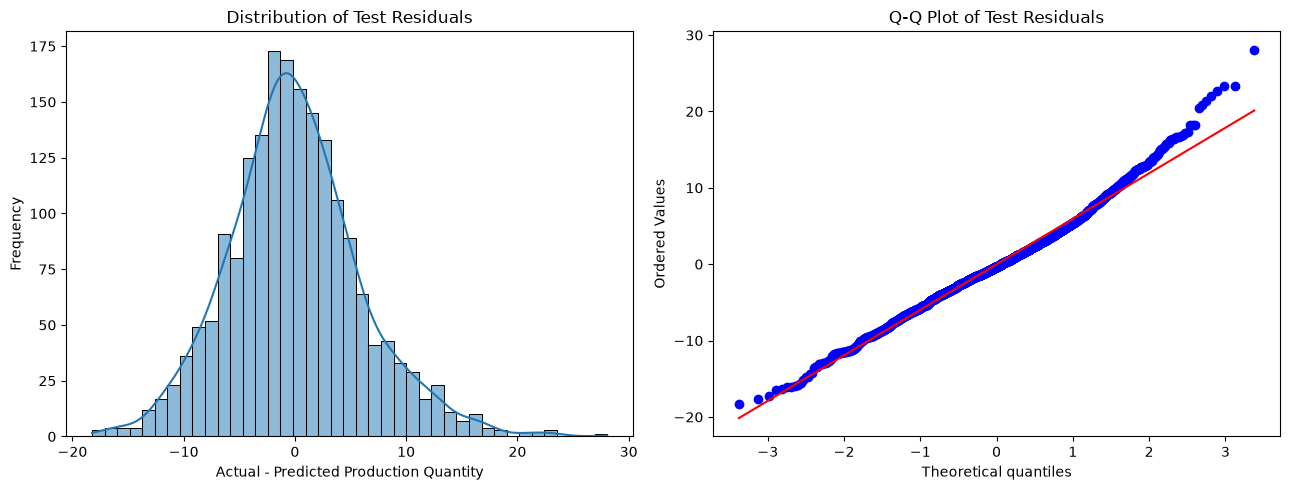

Residual mean: -0.013
Residual standard deviation: 5.988


In [46]:


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Calculate residuals on the chronological test set
residuals = y_test - tuned_test_pred

# Create residual diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Test Residuals')
axes[0].set_xlabel('Actual - Predicted Production Quantity')
axes[0].set_ylabel('Frequency')

# Normal Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of Test Residuals')

plt.tight_layout()
plt.show()

# Summary statistics
print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))


### 4.1.14 Feature Importance Analysis

Feature importance analysis is used to investigate which input variables contribute most to the predictive performance of the selected tuned model.

Permutation importance is calculated by measuring how much the model's test-set performance deteriorates when the values of one feature are randomly shuffled. A larger increase in MAE indicates that the model relies more heavily on that feature for its predictions.

This method evaluates importance at the original input-column level, so it can be used with the complete preprocessing pipeline without manually interpreting every encoded column. The analysis is performed on the held-out test set after model selection and tuning. Its purpose is interpretation, not further optimisation against the test set.

Importance values describe the model's predictive reliance on the observed data. They do not establish that a feature causes changes in production output, and correlated predictors can share or obscure importance.

,Feature,Importance Mean,Importance Std
0,working_hours,3.9016,0.0997
1,machine_count,3.1684,0.1115
2,item_name,1.2258,0.0560
3,avg_hours_per_worker,0.5678,0.0453
4,bottleneck_flag,0.5428,0.0326
5,size_id,0.1965,0.0270
6,machine_worker_ratio,0.0236,0.0050
7,order_category,0.0166,0.0030
8,product_family,0.0072,0.0024
9,no_of_workers,0.0047,0.0046


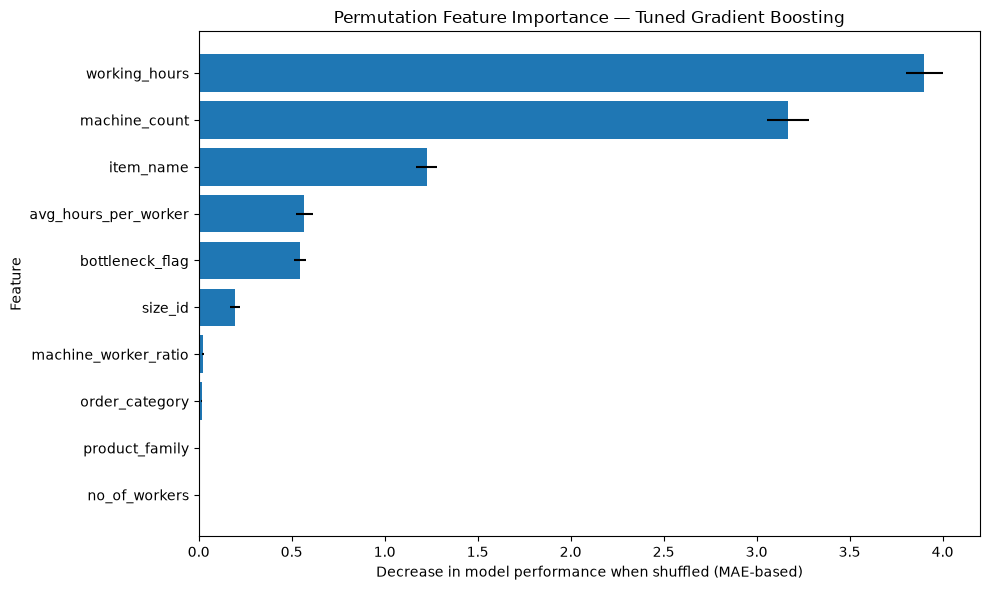

In [47]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the held-out test data
perm_result = permutation_importance(
    tuned_pipeline,
    X_test,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
}).sort_values(
    'Importance Mean',
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values(
    'Importance Mean',
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'],
    top_features['Importance Mean'],
    xerr=top_features['Importance Std']
)
plt.xlabel('Decrease in model performance when shuffled (MAE-based)')
plt.ylabel('Feature')
plt.title('Permutation Feature Importance — Tuned Gradient Boosting')
plt.tight_layout()
plt.show()


# 4.2 Part B – Final Training and Saving

After selecting Gradient Boosting in Part A, the chosen model is retrained using all available production records.

During model selection, only the earlier 80% of records were used for training so that performance could be measured on the most recent 20%. Once the comparison is complete and the model has been selected, the training process can use all available records to learn from the full observed production history.

The final pipeline contains both the preprocessing transformations and the selected regression model. Saving them together ensures that new prediction data undergoes the same transformations used during training.

The final pipeline is saved as `production_model.joblib`. It can then be loaded in the prediction notebook without separately rebuilding the preprocessing steps.

The test metrics recorded in Part A remain the evaluation results for the selected model. Retraining on all records does not create a new independent test result because the final model has now seen the records that previously formed the holdout set.

### 4.2.1 Retrain the Selected Model on All Records

The model identified as the best in Part A is selected automatically using the stored ranking results.

A new pipeline is constructed using the same preprocessing design and a clone of the selected Gradient Boosting estimator.

The pipeline is then fitted on the complete feature dataset, including all 9,495 production records.

Using all available records allows the final model to learn from the full observed production history, including the most recent period that was held out during model comparison.

The fitted pipeline is saved as `production_model.joblib`.

The file contains the complete pipeline rather than only the estimator. This is important because future prediction records must be scaled, encoded, and transformed consistently before being passed to the regression model.

The reported test performance from Part A should continue to be used when describing the model's evaluated performance. The final training step improves the amount of data available for fitting but does not independently verify how the retrained model will perform on future, unseen records.

In [48]:

final_pipeline = clone(tuned_pipeline)
final_pipeline.fit(X_full, y_full)

joblib.dump(
    final_pipeline,
    "../models/production_model.joblib"
)

print("Final tuned model saved successfully.")


Final tuned model saved successfully.


### 4.2.2 Verify the Saved Model

The saved file `production_model.joblib` is reloaded, and the loaded pipeline is used to generate predictions for the last five records in the dataset.

The resulting table compares the recorded `actual_qty` values with the model's predicted quantities. This provides a basic functional check that the saved file can be loaded and used for inference.

The final five records are part of the dataset used to train the final pipeline. Consequently, these predictions are not an independent test of predictive accuracy and should not be used to replace the test metrics reported in Part A.

This step verifies that the model file is usable and that the complete pipeline can accept the feature data and return predictions. A separate evaluation using unseen future observations would be required to measure the final model's performance after deployment.

In [50]:

# Load the final tuned model from the models folder
loaded_model = joblib.load("../models/production_model.joblib")

# Select the last five records for a functionality check
sample = X_full.tail(5)

# Compare actual and predicted production quantities
pd.DataFrame({
    'actual_qty': y_full.tail(5).values,
    'predicted_qty': loaded_model.predict(sample).round().astype(int)
})


,actual_qty,predicted_qty
0,27,25
1,22,25
2,33,35
3,25,28
4,24,30


## 4.3 Summary

This notebook compared seven regression models for predicting `actual_qty` using a chronological training and testing strategy.

Linear Regression was used as the baseline because it provides a simple reference for determining whether more complex algorithms improve forecasting performance. Ridge and Lasso were included to examine regularised linear models, while Random Forest and Extra Trees represented bagged tree ensembles. Gradient Boosting and XGBoost were included to evaluate sequential boosting approaches.

All models were evaluated using R², MAE, and RMSE. The training and test metrics were also compared to identify potential overfitting.

**Gradient Boosting was selected as the best-performing candidate** under the current experimental setup.

Its test results were:

- **R²:** 0.791
- **MAE:** 4.577 production units
- **RMSE:** 6.000 production units
- **Train–test R² gap:** 0.034

The selected model achieved the highest test R² and the lowest test MAE and RMSE among the seven candidates. It also showed a smaller training–test performance gap than the more overfit-prone tree ensembles in this comparison.

After selection, the complete pipeline was retrained on all available records and saved as `production_model.joblib`.

The saved pipeline is intended for the next stage of the project, where predicted actual production quantities can be used to estimate production target achievement and expected production gaps.

The reported test metrics provide the current evidence for the model choice. Future work could examine hyperparameter tuning, additional time-based validation, and prediction errors across different production categories before operational use.
